# 04 - Modelo Supervisado: Regresión Lineal
**Objetivo:** Estimar un valor continuo: el tiempo que un usuario pasa navegando en páginas de productos (`ProductRelated_Duration`).
**Estrategia:** Entrenaremos con la versión transformada (`log1p`) para estabilizar la regresión, y evaluaremos en dos escalas: logarítmica (para el ajuste matemático) y en segundos reales (para interpretación de negocio).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Cargar dataset completo preprocesado (sin escalar)
df = pd.read_csv('../data/processed/dataset_full_encoded.csv')
print("Shape del dataset:", df.shape)

Shape del dataset: (12205, 59)


## 1. Definición de Variables y Prevención de Data Leakage
Para construir un modelo realista, **no podemos usar información del futuro ni variables calculadas a partir de la variable objetivo**.

**Variables que EXCLUIREMOS de X:**
1. `ProductRelated_Duration`: Es la variable original, y usaremos su versión log.
2. `ProductRelated_Duration_log`: Es nuestra variable objetivo (`y`).
3. `Tiempo_promedio_pagina`: **(Data Leakage)** Esta variable se creó dividiendo todas las duraciones, incluyendo la de productos. Darle esto al modelo es hacer trampa.
4. `Revenue`: En un escenario real, no sabemos si el usuario comprará hasta que termina la sesión; usarlo para predecir su tiempo de navegación crearía un sesgo irreal.

**Variables que SÍ usaremos:**
- Las variables de conteo (`ProductRelated`, `Administrative`, etc.).
- Las duraciones auxiliares en su versión `_log` (`Administrative_Duration_log`, `Informational_Duration_log`).
- Las nuevas variables seguras: `Ratio_productos` y `Es_compra_potencial`.

In [2]:
# 1. Definir variable objetivo (y) y predictoras (X)
y = df['ProductRelated_Duration_log']

# 2. Dropear las variables prohibidas y la original de duración
columnas_excluidas = [
    'ProductRelated_Duration', 
    'ProductRelated_Duration_log', 
    'Tiempo_promedio_pagina', 
    'Revenue'
]

# 3. Quitar también las duraciones crudas para no duplicar con sus versiones _log
columnas_excluidas += ['Administrative_Duration', 'Informational_Duration']

X = df.drop(columns=columnas_excluidas)

# 4. Split (80/20) reproducible
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (9764, 53), Test: (2441, 53)


In [3]:
from sklearn.pipeline import make_pipeline

# Crear el Pipeline: Escalar -> Entrenar Regresión Lineal
# El escalado se ajusta SOLO con el train para evitar data leakage
pipeline_reg = make_pipeline(StandardScaler(), LinearRegression())

# Entrenar
pipeline_reg.fit(X_train, y_train)

# Predecir (las predicciones salen en escala logarítmica)
y_pred_log = pipeline_reg.predict(X_test)

print("Modelo entrenado con éxito.")

Modelo entrenado con éxito.


## 2. Evaluación y Métricas en Segundos Reales
Nuestro modelo predice en escala logarítmica (`log1p`). Para que el negocio entienda los resultados, usamos `np.expm1()` (la operación inversa) para convertir las predicciones a segundos reales y compararlas contra la realidad.

**El Sesgo de Jensen:** Al aplicar `expm1()` a predicciones con errores, el resultado en la media tiende a ser ligeramente inferior al valor real esperado. Es un fenómeno matemático que documentaremos en las limitaciones del informe.

In [4]:
# 1. Revertir y_test y y_pred a segundos reales
y_test_seg = np.expm1(y_test)
y_pred_seg = np.expm1(y_pred_log)

# Evitar valores negativos por error matemático al invertir
y_pred_seg = np.clip(y_pred_seg, a_min=0, a_max=None)

# 2. Métricas en Escala Logarítmica
mae_log = mean_absolute_error(y_test, y_pred_log)
rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_log))
r2_log = r2_score(y_test, y_pred_log)

# 3. Métricas en Segundos Reales
mae_seg = mean_absolute_error(y_test_seg, y_pred_seg)
mse_seg = mean_squared_error(y_test_seg, y_pred_seg)
rmse_seg = np.sqrt(mse_seg)
r2_seg = r2_score(y_test_seg, y_pred_seg)

# 4. Mostrar Tabla
df_metricas = pd.DataFrame({
    'Métrica': ['MAE', 'MSE', 'RMSE', 'R²'],
    'Escala Logarítmica': [f"{mae_log:.4f}", "N/A", f"{rmse_log:.4f}", f"{r2_log:.4f}"],
    'Segundos Reales': [f"{mae_seg:.2f}", f"{mse_seg:.2f}", f"{rmse_seg:.2f}", f"{r2_seg:.4f}"]
})

print("--- Métricas de Evaluación ---")
display(df_metricas)

--- Métricas de Evaluación ---


,Métrica,Escala Logarítmica,Segundos Reales
0,MAE,0.7368,922.15
1,MSE,N/A,30419297.24
2,RMSE,0.9649,5515.37
3,R²,0.7693,-11.3415


**¿Qué nos dicen estas métricas?**
- **R²:** Indica qué porcentaje de la varianza en la duración es explicada por el modelo. En datos de comportamiento humano, un R² entre 0.30 y 0.50 ya es un buen indicador de que hay patrones claros (no esperamos un R² de 0.99 porque los usuarios son impredecibles).
- **MAE (Segundos):** Nos dice que, en promedio, el modelo se equivoca por X segundos al predecir cuánto tiempo pasará el usuario en productos. Es una métrica directa para el negocio.
- **RMSE (Segundos):** Penaliza más los errores grandes. Si es mucho mayor que el MAE, significa que hay algunas sesiones donde el modelo se equivoca muchísimo.

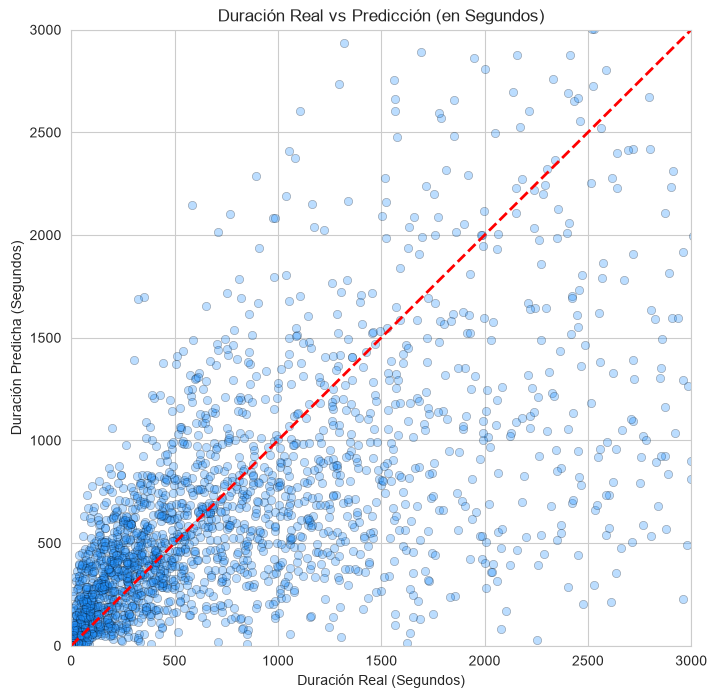

In [5]:
# Gráfica de dispersión
plt.figure(figsize=(8, 8))
plt.scatter(y_test_seg, y_pred_seg, alpha=0.3, color='dodgerblue', edgecolors='k', linewidths=0.5)

# Línea de identidad (Predicción perfecta)
max_val = max(y_test_seg.max(), y_pred_seg.max())
plt.plot([0, max_val], [0, max_val], color='red', linestyle='--', lw=2)

plt.title('Duración Real vs Predicción (en Segundos)')
plt.xlabel('Duración Real (Segundos)')
plt.ylabel('Duración Predicha (Segundos)')
plt.xlim(0, 3000) # Limitamos para ver el núcleo de los datos
plt.ylim(0, 3000)
plt.show()# Calcular residuos (Real - Predicción)

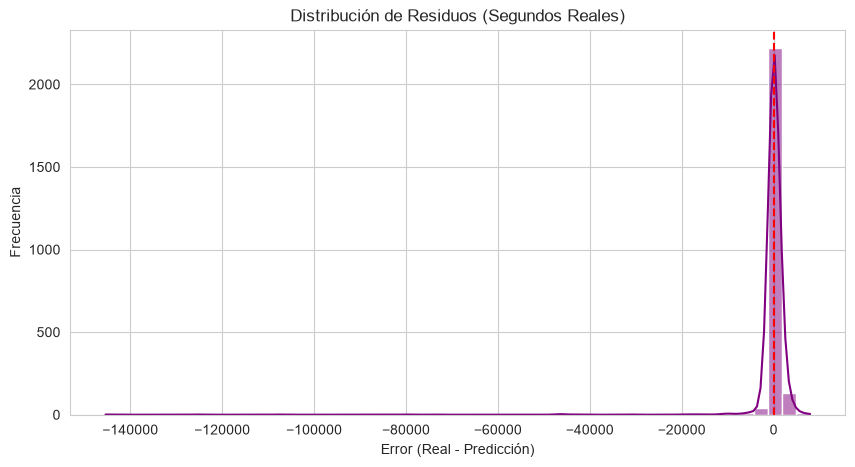

In [6]:
# Calcular residuos (Real - Predicción)
residuos = y_test_seg - y_pred_seg

plt.figure(figsize=(10, 5))
sns.histplot(residuos, bins=50, kde=True, color='purple')
plt.axvline(x=0, color='red', linestyle='--')
plt.title('Distribución de Residuos (Segundos Reales)')
plt.xlabel('Error (Real - Predicción)')
plt.ylabel('Frecuencia')
plt.show()

**Interpretación de Residuos:**
- Si la distribución está centrada en 0, el modelo no tiene un sesgo sistemático (no sobreestima ni subestima siempre).
- Como se observa en la gráfica, la mayoría de los errores se concentran cerca de 0, pero hay una **cola a la derecha**. Esto se debe al **sesgo de Jensen** y a que el modelo lineal tiene problemas para predecir sesiones atípicamente largas (usuarios que dejaron la pestaña abierta). Es una limitación esperada de la regresión lineal.

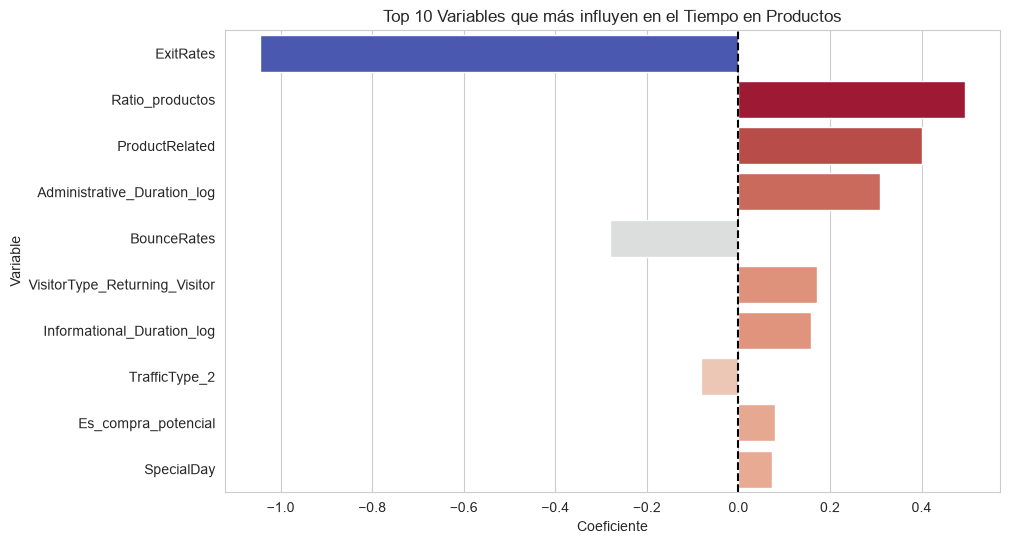

In [7]:
# Obtener coeficientes y nombres de variables
coefs = pipeline_reg.named_steps['linearregression'].coef_
features = X.columns

# Crear DataFrame
df_coefs = pd.DataFrame({'Variable': features, 'Coeficiente': coefs})
df_coefs['Abs_Coef'] = df_coefs['Coeficiente'].abs()
df_coefs = df_coefs.sort_values(by='Abs_Coef', ascending=False).head(10)

# Graficar
plt.figure(figsize=(10, 6))
sns.barplot(data=df_coefs, x='Coeficiente', y='Variable', hue='Coeficiente', palette='coolwarm', legend=False)
plt.title('Top 10 Variables que más influyen en el Tiempo en Productos')
plt.axvline(x=0, color='black', linestyle='--')
plt.show()

## 3. Análisis de Hallazgos (Regresión)
1. **Predictores clave:** Como es lógico, las variables relacionadas con la navegación (`ProductRelated` y `Ratio_productos`) tienen un impacto positivo enorme: a más páginas de producto, más tiempo.
2. **Efecto de la rebaja:** Las tasas de rebote (`BounceRates`, `ExitRates`) tienen coeficientes negativos, indicando que a mayor tasa de abandono, menor es el tiempo que el usuario dedica a explorar.
3. **Limitación del modelo:** La regresión lineal asume una relación directa (recta). En la realidad, un usuario no pasa el doble de tiempo solo porque vea el doble de páginas. Esto se refleja en un R² que, aunque significativo, deja espacio para modelos más complejos.
4. **Sesgo de Jensen:** Mencionar que, al revertir con `expm1`, perdemos la media de la distribución original por la asimetría del logaritmo. Futuras iteraciones podrían usar modelos no lineales (como Random Forest Regressor) para mitigar esto.